In [70]:
# imports
import pandas as pd
import numpy as np
import seaborn as sns
from scipy.spatial import ConvexHull
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt

In [71]:
# import data: drafted RBs since 2017 with their college stats (from the player comps project)
df = pd.read_csv('csv/rb_comps.csv')
df.columns

Index(['draft', 'pick', 'player', 'att', 'yds', 'y_a', 'td', 'fumbles',
       'off_grade', 'run_grade', 'yaco_a', 'mtf', 'lng', '10_plus', 'bay_pct',
       'first', 'tgt', 'rec', 'rec_yds', 'y_rr', 'drp', 'elu',
       'fantasy_finish'],
      dtype='object')

In [72]:
df

,draft,pick,player,att,yds,y_a,td,fumbles,off_grade,run_grade,...,10_plus,bay_pct,first,tgt,rec,rec_yds,y_rr,drp,elu,fantasy_finish
0,2026,3,Jeremiyah Love,199,1372.0,6.9,18,1,93.1,93.7,...,39,52.9,63,34,27,280,1.83,1,127.5,NaN
1,2026,32,Jadarian Price,113,674.0,6.0,11,3,78.6,79.9,...,24,45.0,35,7,6,87,1.23,0,118.6,NaN
2,2026,90,Kaelon Black,186,1034.0,5.6,10,2,83.7,85.5,...,26,40.7,51,7,5,42,0.31,0,58.2,NaN
3,2026,108,Jonah Coleman,157,758.0,4.8,15,2,82.1,83.8,...,20,33.4,55,34,31,346,1.73,0,85.7,NaN
4,2026,122,Mike Washington Jr,167,1066.0,6.4,8,3,78.3,84.3,...,30,48.3,52,36,28,226,0.99,1,73.2,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
99,2017,121,Joe Williams,210,1389.0,6.6,10,5,65.6,67.1,...,36,48.2,62,13,9,107,0.79,3,54.6,4.0
100,2017,132,Donnel Pumphrey,350,2132.0,6.1,17,2,76.2,75.3,...,59,47.0,96,39,27,236,1.17,3,68.4,4.0
101,2017,134,Jamaal Williams,235,1371.0,5.8,12,2,81.7,80.5,...,34,43.3,65,7,6,74,0.54,0,77.7,2.0
102,2017,140,Wayne Gallman,232,1131.0,4.9,17,2,75.4,77.8,...,28,28.0,61,26,20,143,0.54,1,72.1,3.0


In [ ]:
# K-Means is unsupervised, so there is no y and no train/test split
# Some stats are bad when they are high (fumbles, drops), how can we modify the numbers so the model sees that?
# How can we alter pick so lower pick is better?
df['fumbles'] = df['fumbles'] *
df['drp'] = df['drp'] *
df['pick_value'] = df['pick']

features = ['pick_value', 'att', 'yds', 'y_a', 'td', 'fumbles', 'off_grade', 'run_grade',
            'yaco_a', 'mtf', 'lng', '10_plus', 'bay_pct', 'first',
            'tgt', 'rec', 'rec_yds', 'y_rr', 'drp', 'elu']
X = df[features]

In [74]:
# K-Means works on distance just like KNN, so the columns need to be on the same scale
# yds goes into the 1000s while y_a is around 6, so yds would run the whole thing
X.describe().loc[['min', 'max']]

,pick_value,att,yds,y_a,td,fumbles,off_grade,run_grade,yaco_a,mtf,lng,10_plus,bay_pct,first,tgt,rec,rec_yds,y_rr,drp,elu
min,0.006944,16.0,31.0,1.9,1.0,-7.0,65.3,66.2,2.42,4.0,11.0,2.0,0.0,4.0,3.0,2.0,21.0,0.18,-5.0,25.1
max,0.500000,375.0,2595.0,8.9,29.0,0.0,95.3,97.0,6.16,152.0,95.0,63.0,70.8,120.0,65.0,55.0,625.0,3.38,0.0,216.5


In [75]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [76]:
# K-Means = pick K random centers, assign every player to the closest center,
# move each center to the average of its players, and repeat until nothing moves
# n_clusters = K, how many groups we want (we pick this ourselves)
# n_init = how many random starting points to try, it keeps the best one
kmeans = KMeans(n_clusters=4, n_init=10, random_state=42)
df['cluster'] = kmeans.fit_predict(X_scaled)

df['cluster'].value_counts().sort_index()

0    21
1    30
2    36
3    17
Name: cluster, dtype: int64

In [ ]:
df.groupby('cluster')[features].mean().round(2)

,pick_value,att,yds,y_a,td,fumbles,off_grade,run_grade,yaco_a,mtf,lng,10_plus,bay_pct,first,tgt,rec,rec_yds,y_rr,drp,elu
cluster,,,,,,,,,,,,,,,,,,,,
0,0.06,256.90,1687.43,6.60,19.48,-2.14,89.99,91.04,4.26,79.67,74.95,47.67,47.08,83.86,35.38,28.33,302.52,1.46,-1.86,136.18
1,0.01,248.17,1388.03,5.62,15.57,-2.23,83.20,84.13,3.41,59.17,64.80,37.87,39.08,73.97,23.90,19.50,151.93,0.83,-1.37,83.74
2,0.03,163.83,984.14,6.08,10.44,-1.11,83.67,85.00,3.72,40.47,66.31,27.92,45.20,48.42,37.53,30.83,299.39,1.52,-1.86,98.96
3,0.01,137.24,698.65,4.89,7.29,-1.35,76.19,77.14,3.06,27.06,48.65,19.71,35.24,36.00,16.00,12.88,94.82,0.88,-0.76,69.04


In [ ]:
for c in sorted(df['cluster'].unique()):
    print(f"Cluster {c}:", ', '.join(df[df['cluster'] == c]['player'].head(8)))

Cluster 0: Jeremiyah Love, Ashton Jeanty, Omarion Hampton, RJ Harvey, Kaleb Johnson, Cam Skattebo, Bijan Robinson, Zach Charbonnet
Cluster 1: Quinshon Judkins, Bhayshul Tuten, Jarquez Hunter, Dylan Sampson, Blake Corum, Brealon Allen, Kendre Miller, Breece Hall
Cluster 2: Jonah Coleman, Mike Washington Jr, TreVeyon Henderson, Woody Marks, Jonathon Brooks, Trey Benson, MarShawn Lloyd, Jaylen Wright
Cluster 3: Jadarian Price, Kaelon Black, Trevor Etienne, Will Shipley, Tyrion Davis-Price, Zamir White, Kene Nwangwu, Chuba Hubbard


In [ ]:
# n_clusters: the number of groups we want, n_init: the amount of randomly placed centers we have
kmeans = KMeans(n_clusters=4, n_init=10, random_state=42)
df['cluster'] = kmeans.fit_predict(X_scaled)

In [ ]:
cluster_names = {0: 'Elite', 1: 'Low Upside', 2: 'High Upside', 3: 'Avoid'}

df['cluster_name'] = df['cluster'].map(cluster_names)
df['cluster_name'].value_counts()

High Upside    36
Low Upside     30
Elite          21
Avoid          17
Name: cluster_name, dtype: int64

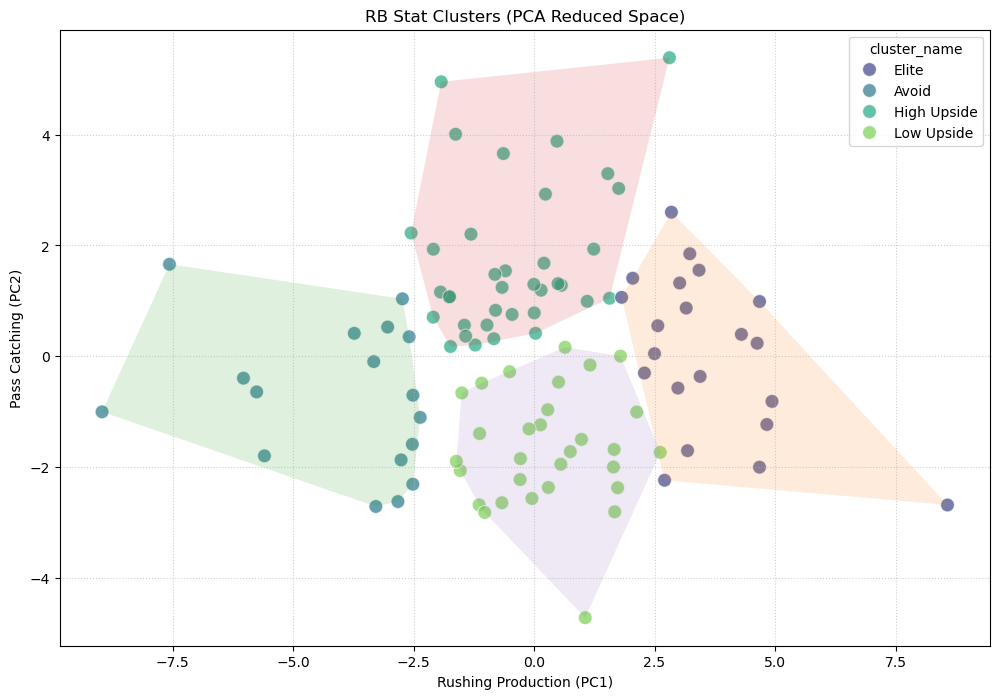

In [81]:
# We can't plot 20 columns, so squish them down to 2 with PCA and color by cluster
# PCA only makes the plot, the clusters were still found using all 20 columns
pca = PCA(n_components=2)
components = pca.fit_transform(X_scaled)
df['PC1'] = components[:, 0]
df['PC2'] = components[:, 1]

plt.figure(figsize=(12, 8))
sns.scatterplot(data=df, x='PC1', y='PC2', hue='cluster_name', palette='viridis',
                s=100, alpha=0.7, edgecolor='w')

# draw a shaded outline around each cluster
for name in df['cluster_name'].unique():
    points = df[df['cluster_name'] == name][['PC1', 'PC2']].values
    if len(points) >= 3:
        hull = ConvexHull(points)
        hull_indices = np.append(hull.vertices, hull.vertices[0])
        plt.fill(points[hull_indices, 0], points[hull_indices, 1], alpha=0.15)

plt.title('RB Stat Clusters (PCA Reduced Space)')
# axis names come from the loadings in the next cell: PC1 is mostly rushing production, PC2 is mostly pass catching
plt.xlabel('Rushing Production (PC1)')
plt.ylabel('Pass Catching (PC2)')
plt.grid(True, linestyle=':', alpha=0.6)
plt.show()

In [82]:
# What do PC1 and PC2 actually mean? Look at which stats pull on each one (the loadings)
# This is how you decide what to call the axes
loadings = pd.DataFrame(pca.components_.T, index=features, columns=['PC1', 'PC2'])
print(loadings.sort_values('PC1', ascending=False).round(2)['PC1'].head(5))
print(loadings.sort_values('PC2', ascending=False).round(2)['PC2'].head(5))

yds        0.32
10_plus    0.32
mtf        0.31
first      0.30
td         0.28
Name: PC1, dtype: float64
rec_yds    0.41
rec        0.38
tgt        0.38
y_rr       0.36
fumbles    0.18
Name: PC2, dtype: float64


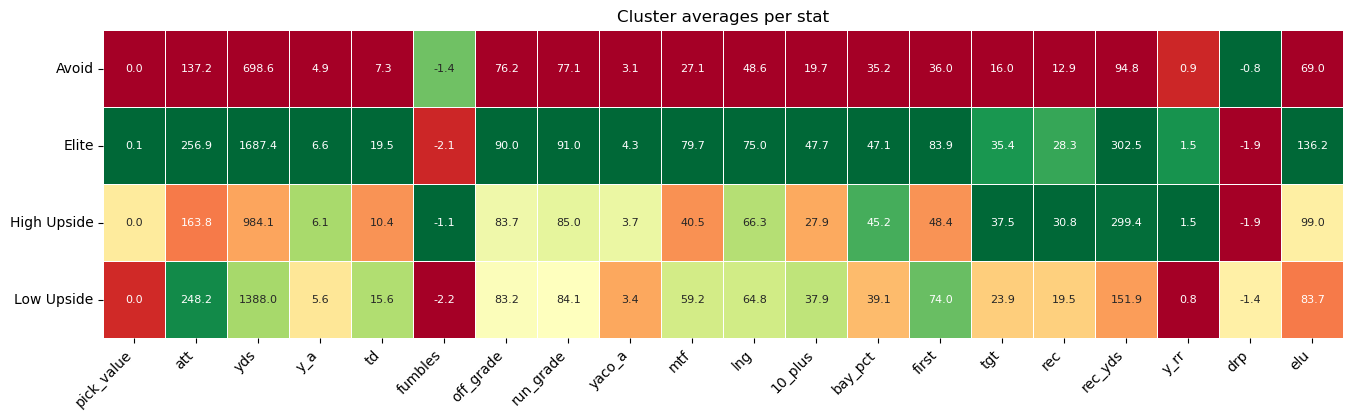

In [ ]:
means = df.groupby('cluster_name')[features].mean()
norm = (means - means.min()) / (means.max() - means.min())

plt.figure(figsize=(16, 4))
sns.heatmap(norm, annot=means.round(1), fmt='', cmap='RdYlGn', cbar=False,
            linewidths=0.5, annot_kws={'fontsize': 8})
plt.title('Cluster averages per stat')
plt.ylabel('')
plt.xticks(rotation=45, ha='right')
plt.show()

In [84]:
hist = df.dropna(subset=['fantasy_finish']).copy()
hist['RB1'] = hist['fantasy_finish'] == 1
hist['RB2+'] = hist['fantasy_finish'] <= 2
hist['RB3+'] = hist['fantasy_finish'] <= 3
hist['Bad'] = hist['fantasy_finish'] == 4

(hist.groupby('cluster_name')[['RB1', 'RB2+', 'RB3+', 'Bad']].mean() * 100).round(1)

,RB1,RB2+,RB3+,Bad
cluster_name,,,,
Avoid,0.0,13.3,26.7,73.3
Elite,40.0,65.0,80.0,20.0
High Upside,38.2,52.9,61.8,38.2
Low Upside,10.0,30.0,46.7,53.3


In [85]:
rookies = df[df['fantasy_finish'].isna()]
rookies[['player', 'pick', 'cluster_name']]

,player,pick,cluster_name
0,Jeremiyah Love,3,Elite
1,Jadarian Price,32,Avoid
2,Kaelon Black,90,Avoid
3,Jonah Coleman,108,High Upside
4,Mike Washington Jr,122,High Upside


In [86]:
# Comps: for each rookie, find the closest past players by distance in the scaled space
# This is the same idea as the neighbors in KNN
past = df['draft'] < 2026

def get_comps(player, n=3):
    idx = df[df['player'] == player].index[0]
    distances = ((X_scaled - X_scaled[idx]) ** 2).sum(axis=1) ** 0.5

    comps = df[past][['draft', 'player', 'cluster_name']].copy()
    comps['distance'] = distances[past].round(2)
    return comps.sort_values('distance').head(n)

for player in rookies['player']:
    print(f"\n{player} ({df.loc[df['player'] == player, 'cluster_name'].iloc[0]})")
    print(get_comps(player).to_string(index=False))


Jeremiyah Love (Elite)
 draft             player cluster_name  distance
  2023     Bijan Robinson        Elite      4.62
  2017 Leonard Fournette*        Elite      5.00
  2023       Tyjae Spears        Elite      5.44

Jadarian Price (Avoid)
 draft         player cluster_name  distance
  2020  DeeJay Dallas        Avoid      2.70
  2024 MarShawn Lloyd  High Upside      3.04
  2017  Samaje Perine        Avoid      3.39

Kaelon Black (Avoid)
 draft             player cluster_name  distance
  2022        Zamir White        Avoid      2.24
  2017    Jamaal Williams   Low Upside      2.49
  2022 Tyrion Davis-Price        Avoid      2.68

Jonah Coleman (High Upside)
 draft         player cluster_name  distance
  2025 Trevor Etienne        Avoid      2.57
  2019    Josh Jacobs  High Upside      3.16
  2022     James Cook  High Upside      3.48

Mike Washington Jr (High Upside)
 draft        player cluster_name  distance
  2020 D'Andre Swift   Low Upside      2.08
  2024 Brealon Allen   Low 